# Testing inference: how many neurons must the trigger recruit?

Companion to notebook 15: instead of truncating the trigger *in time*, this notebook
lesions it *in space* - the first `N_neuron` rows (neuron addresses) of the trigger are
silenced. It measures how much of the stored population code must be cued before the
network re-emits the complete memory: pattern completion along the *neuronal* axis.

## Notebook summary

### Pipeline
1. Load the trained `<datetag>_vanilla.pth` (weights from notebook 11, no retraining).
2. Single trial silencing `N_neuron // 32 = 32` trigger neurons -> F1 + raster.
3. Scan the number of silenced neurons from 0 to `N_neuron` in `N_scan=14` steps
      (`Params` default) x `N_cv=11` seeded repetitions (`get_scores_fraction`) ->
      `<datetag>_N_neurons.npz` (+ `.lock`); plot `fraction_target_score.pdf`.
4. Theory: ignition model of the replay (`get_f1_ignition`, with a fraction
      `1 - n / N_neuron` of the neurons shown), overlaid on `fraction_target_score.pdf`.

### Main outputs
- cache `../cached_data/<datetag>_N_neurons.npz` (arrays `N_neurons`, `scores_np`);
- figures `fraction_target.pdf` (raster) and `fraction_target_score.pdf` (F1 vs number
     of inactive trigger neurons).


In [1]:
# Shared helpers from mnesis_boilerplate; model/algorithm from mnesis_chains.

from mnesis_boilerplate import torch, np, plt, splt, data_cache, figpath, RECOMPUTE, Params
from mnesis_boilerplate import printfig, get_scores, get_f1score, get_beta_errorbar, trange
from mnesis_boilerplate import get_f1_ignition
from mnesis_chains import load
# RECOMPUTE = True

datetag = '2026-09-07'
Using device: mps


In [2]:
# Load the trained vanilla readout (frozen target reproduced from the same seed).

opt = Params() # type: ignore
model_filename = data_cache / f"{opt.datetag}_vanilla.pth"
hd = load(opt, model_filename)
print(f"Model weights loaded from {model_filename}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth


## Retrieval from a partial trigger (spatial lesion)

Silencing `N_neuron // 32` neurons is a *hidden* ablation: those neurons' spikes are
removed from the cue only, but they still belong to the target and must be re-emitted
from the remaining 31/32 of the population.

In [3]:
# N_neuron//32 trigger neurons are silenced in the window [N_pretime, N_pretime+num_delay).

with torch.no_grad():
    target = hd.pattern_object.frozen_target # noise-free reference, scored against
    cue = hd.pattern_object(seed=hd.opt.seed) # seeded noisy realisation, provides the trigger
    target_full = torch.nn.functional.pad(target, (opt.N_pretime, opt.N_pretime))
    input_spikes = hd.get_input_spikes(target=cue, seed=hd.opt.seed)
    input_spikes[:, :(opt.N_neuron//32), (hd.opt.N_pretime):(hd.opt.N_pretime+hd.opt.num_delay)] *= 0
    _, _, spikes = hd.forward_pass(input_spikes)
    spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]
    target_evoked = target[:, :, hd.opt.num_delay:]

    precision, recall, f1_score = get_scores(spikes_evoked, target_evoked)
    print(f'precision = {precision:.3f}\t recall = {recall:.3f}\t f1_score = {f1_score:.3f} ')

precision = 0.823	 recall = 0.761	 f1_score = 0.791 


### Raster of the lesioned-trigger trial

Legend as in notebook 11 (green `x` trigger, red `o` target, blue `+` evoked; dashed
verticals at `N_pretime` and `N_pretime + num_delay`): the top of the green trigger band
is missing (lesioned neurons), yet red targets remain there.

Saving as ../figures/fraction_target.pdf
Saving as ../figures/fraction_target.png
Saving as ../figures/fraction_target.svg


(torch.Size([16, 1024, 1100]), 265.0, 140.0)

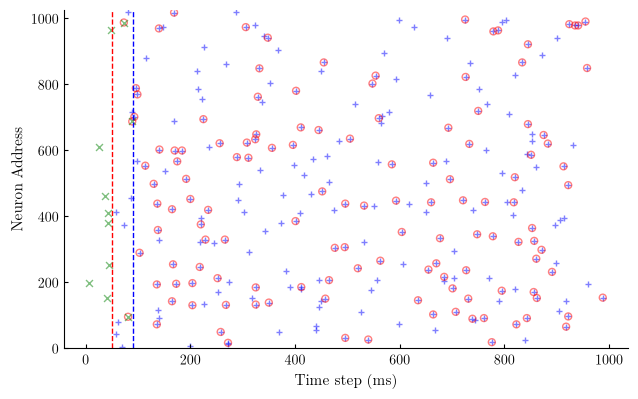

In [4]:
fig, ax = plt.subplots()
splt.raster(spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="blue", marker='+', alpha=.5)
splt.raster(target_full[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, facecolor='none', edgecolor='red',  marker='o', alpha=.5)
splt.raster(input_spikes[opt.i_pattern, :opt.N_neuron_show, :opt.N_time_show].T, ax, s=25, c="green", marker='x', alpha=.5)
ax.vlines([opt.N_pretime], 0, opt.N_neuron_show, 'r', ls='--')
ax.vlines([opt.N_pretime+opt.num_delay], 0, opt.N_neuron_show, 'b', ls='--')
ax.set_xlabel("Time step (ms)")
ax.set_ylabel("Neuron Address")
ax.set_ylim(-1., opt.N_neuron_show + 1.)
printfig(fig, 'fraction_target', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)
spikes.shape, spikes[opt.i_pattern, :, :].sum().item(), target[opt.i_pattern, :, :].sum().item()

## Sweep: F1-score for different numbers of silenced trigger neurons

`get_scores_fraction`: `N_scan=36` values linspace(0, N_neuron) of silenced rows;
one trigger + forward pass + evoked-window `get_f1score` each. The curve locates the
*robustness threshold* - how large a lesion before the memory fails to ignite.
Cached as `<datetag>_N_neurons.npz` under the `.lock` protocol.

In [5]:
# One cue realisation per repetition (seeded nb 20-style); the spatial lesion is re-
# applied to each fresh cue and scored against the clean frozen_target; the cache is
# saved after every lesion size (with an n_done sentinel) so an interrupted run can
# resume from the file and a partial file is never mistaken for a complete one.

def get_scores_fraction(N_scan=opt.N_scan, N_cv=opt.N_cv):
    N_neurons = np.linspace(0, hd.opt.N_neuron, N_scan, endpoint=True, dtype=int)
    scores_np = np.zeros((N_scan, N_cv))
    target_evoked = hd.pattern_object.frozen_target[:, :, hd.opt.num_delay:]
    seed = hd.opt.seed # base seed, incremented per repetition (nb 20 convention)
    for i_N_neuron in trange(N_scan):
        N_neuron = N_neurons[i_N_neuron]
        for i_cv in range(N_cv):
            with torch.no_grad():
                target_ = hd.pattern_object(seed=seed)
                input_spikes = hd.get_input_spikes(target=target_, seed=seed)
                input_spikes[:, :(N_neuron), (hd.opt.N_pretime):(hd.opt.N_pretime+hd.opt.num_delay)] *= 0
                _, _, spikes = hd.forward_pass(input_spikes)
                spikes_evoked = spikes[:, :, (hd.opt.N_pretime+hd.opt.num_delay):(hd.opt.N_time+hd.opt.N_pretime)]

                scores_np[i_N_neuron, i_cv] = get_f1score(spikes_evoked, target_evoked)
                seed += 1

        np.savez(npy_filename, N_neurons=N_neurons, scores_np=scores_np, n_done=i_N_neuron + 1) # incremental save

    return N_neurons, scores_np

npy_filename = data_cache / f"{hd.opt.datetag}_N_neurons.npz"
lock_filename = npy_filename.with_suffix('.lock')
if RECOMPUTE:
    npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
try:
    data = np.load(npy_filename)
    N_neurons = data['N_neurons']
    scores_np = data['scores_np']
    if data['scores_np'].shape != (opt.N_scan, opt.N_cv) or ('n_done' not in data) or (data['n_done'] != opt.N_scan):
        raise ValueError(f"Partial score file: {npy_filename}, re-evaluating.")
    lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
    print(f"Score weights loaded from {npy_filename}") # Add a log message
except (FileNotFoundError, ValueError):
    if not lock_filename.exists():
        print(f"Score file not found: {npy_filename}, evaluating the score.")
        lock_filename.touch(exist_ok=True)
         ##################
        N_neurons, scores_np = get_scores_fraction()
         ##################
        np.savez(npy_filename, N_neurons=N_neurons, scores_np=scores_np, n_done=opt.N_scan)
        lock_filename.unlink(missing_ok=True)
    else:
        print(f"Score file is locked: {lock_filename}, passing.")

Score file not found: ../cached_data/2026-09-07_N_neurons.npz, evaluating the score.


100%|██████████| 14/14 [03:28<00:00, 14.88s/it]


In [6]:
# sanity check that scan vectors are aligned.

N_neurons.shape, scores_np.shape

((14,), (14, 11))

## Expected F1 from theory

The ignition model of notebook 14 (`get_f1_ignition`) applies to a trigger in which $n$ of the
$N$ neurons are silenced. A spike supporting the first evoked spikes is present with probability

$$q = \Big(1 - \frac{n}{N}\Big)\big(1 - p_\mathrm{flip}\,(1 - p_A)\big),$$

where $p_\mathrm{flip}$ is the bit-flip probability of the cue and $p_A$ the firing probability
of the motif. A spike of the motif is emitted if at least $\lceil \vartheta K \rceil$ of its $K$
supporting spikes are present, with $\vartheta$ the firing threshold and $K$ a Poisson variable
of mean $\lambda = p_A N D$ ($D$ bins in the spiking-motif window), and the replay of a motif
ignites with probability

$$R(n) = \Phi(q) = \sum_{K \geq 1} \frac{e^{-\lambda} \lambda^K}{K!} \sum_{k = \lceil \vartheta K \rceil}^{K} \binom{K}{k}\, q^k (1 - q)^{K - k}$$

As with flips, the missing spikes are scattered across the window, so the first evoked spikes
soon replace the lesioned trigger: there is no lasting deficit, unlike the truncated trigger of
notebook 15. As in notebook 14, $F_1 = 2\, R\, r_0 / (1 + R\, r_0 / \pi_0)$, with $\pi_0$ and
$r_0$ the precision and recall with the intact trigger ($n = 0$); the threshold is the LIF
threshold of the network, not a fitted value. The model averages over random sets of supporting
spikes, whereas the lesion always silences the same addresses (0 to $n - 1$): with $M = 16$
motifs, the few motifs whose trigger spikes mostly fall on high addresses keep igniting, which
can leave a plateau above the curve.

| symbol | name in the code | default value | role |
|---|---|---|---|
| $n$ | `N_neurons` | swept from 0 to 1024 in 14 steps | number of silenced trigger neurons |
| $N$ | `N_neuron` | 1024 | number of neurons |
| $D$ | `num_delay` | 41 bins (41 ms) | width of the spiking-motif window |
| $p_\mathrm{flip}$ | `p_flip` | 0.01 | bit-flip probability of the cue |
| $p_A$ | `p_A` | $1.6 \times 10^{-4}$ per 1 ms bin (0.16 Hz) | firing probability of the motif |
| $\vartheta$ | `lif_threshold` | 0.75 | firing threshold, relative to the membrane potential reached on the motif |
| $\lambda$ | `p_A * N_neuron * num_delay` | 6.72 | mean number of spikes supporting a spike of the motif |
| $q$ | `fraction * (1 - p_flip * (1 - p_A))` | - | probability that a supporting spike is present in the trigger |
| $\Phi$ | - | - | probability that a spike of the motif is emitted |
| $R$ | - | - | probability that the replay of a motif ignites |
| $\pi_0$, $r_0$ | `precision_0`, `recall_0` | measured with $n = 0$ | precision and recall with the intact trigger |

The cell below measures $\pi_0$ and $r_0$ with the first repetition of the sweep protocol (same
seed, no lesion), evaluates the ignition model, and reports its RMS error on the sweep. In the
score figure, the dashed black line is this $F_1$.

In [7]:
# Precision and recall of the replay with the intact trigger (first repetition of the sweep
# protocol, same seed): the only measured inputs of the ignition model.

with torch.no_grad():
    target_ = hd.pattern_object(seed=opt.seed)
    _, _, spikes = hd.forward_pass(hd.get_input_spikes(target=target_, seed=opt.seed))
    spikes_evoked = spikes[:, :, (opt.N_pretime+opt.num_delay):(opt.N_time+opt.N_pretime)]
    target_evoked = hd.pattern_object.frozen_target[:, :, opt.num_delay:]
    precision_0, recall_0, f1_score_0 = [score.item() for score in get_scores(spikes_evoked, target_evoked)]
print(f'intact trigger: precision = {precision_0:.3f}\t recall = {recall_0:.3f}\t f1_score = {f1_score_0:.3f}')

theory_dict = dict(p_flip=opt.p_flip, p_A=opt.p_A, N_neuron=opt.N_neuron, num_delay=opt.num_delay,
                   lif_threshold=opt.lif_threshold, precision_0=precision_0, recall_0=recall_0)
# lesioned trigger: a fraction 1 - n / N of the neurons is shown, the losses are scattered
N_neurons_theory = np.linspace(0, opt.N_neuron, 201)
f1_ignition_theory = get_f1_ignition(fraction=1 - N_neurons_theory/opt.N_neuron, **theory_dict)
if not lock_filename.exists():
    f1_ignition_scan = get_f1_ignition(fraction=1 - N_neurons/opt.N_neuron, **theory_dict)
    rmse = np.sqrt(np.mean((f1_ignition_scan - scores_np.mean(axis=1))**2))
    print(f'RMS error of the ignition model on the sweep = {rmse:.3f}')

intact trigger: precision = 0.877	 recall = 0.825	 f1_score = 0.850
RMS error of the ignition model on the sweep = 0.066


Saving as ../figures/fraction_target_score.pdf
Saving as ../figures/fraction_target_score.png
Saving as ../figures/fraction_target_score.svg


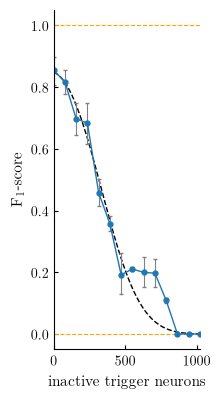

In [8]:
# $F_1$ vs number of inactive trigger neurons, mean and 5%-95% quantiles of a beta fit over N_cv realisations;
# orange guides at 0 and 1; dashed: ignition model.

if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.hlines([0, 1], N_neurons[0], N_neurons[-1], 'orange', ls='--', lw=0.8)
    ax.plot(N_neurons_theory, f1_ignition_theory, color='k', ls='--')
    mean, yerr = get_beta_errorbar(scores_np)
    ax.errorbar(N_neurons, mean, yerr=yerr, fmt='o',
                color='tab:blue', ecolor='0.5', elinewidth=0.8, capsize=1.5,
                markersize=3.5, linestyle='solid', linewidth=1.0)
    ax.set_xlabel(r"inactive trigger neurons")
    ax.set_ylabel(r"$F_1$-score")
    ax.set_xlim(N_neurons[0], N_neurons[-1])
    ax.set_ylim(-0.05, 1.05)

    printfig(fig, 'fraction_target_score', fig_width=opt.fig_width/3, fig_height=opt.fig_height, figpath=figpath)
